Классификация облаков

Цель:
построить модель классификации облачных структур по спутниковым изображениям.
проанализировать результаты классификации для исследования особенностей организации облаков.


Описание/Пошаговая инструкция выполнения домашнего задания:
сформировать нейронную сверточную сеть;
обучить сеть на представленных данных;
оценить качество модели. В качестве критерия используйте Dice coefficient.
датасет для обучения модели: https://www.kaggle.com/competitions/understanding_cloud_organization/data
дополнительная ссылка на датасет для обучения модели: https://drive.google.com/file/d/1leoj71B_D_paBLC1uP5EKcnR5lJFPovn/view

Критерии оценки:
Обученная сеть;
График обучения;
Алгоритм обучения с условием раннего останова по метрике.


Компетенции:
Deep Learning ML
- Знать основы архитектуры нейросетей
- Знать основы обучения нейросетей
- Знать алгоритмы backpropagation и различные вариации градиентного спуска
- Использовать фреймворк PyTorch для работы с моделями глубокого обучения
- Обучать глубокие нейронные сети, справляться с проблемой переобучения и взрыва/затухания градиента
- Применять сверточные сети для распознавания, детектирования и сегментации объектов на изображениях
- Выбирать подходящие архитектуры нейронных сетей для решения поставленных задач

In [1]:
# =====================
# 1. CSV load and setup configs
# =====================

import os
import time
import copy
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')

# Configs
RANDOM_STATE = 555
pd.set_option('display.max_columns', None)

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Directories
input_dir = 'csv_input'
output_dir = 'csv_output'
os.makedirs(output_dir, exist_ok=True)

IMG_DIR = os.path.join(input_dir, 'train_images')

# Train.csv classses
CLASSES = ['Fish', 'Flower', 'Gravel', 'Sugar']

print('PyTorch version:', torch.__version__)
print('Device:', device)

# Load train.csv: one row per image+class, EncodedPixels holds the RLE mask
file_path = os.path.join(input_dir, 'train.csv')

all_cols = pd.read_csv(file_path, nrows=0).columns.tolist()
exclude_cols = []  # columns to drop
use_cols = [col for col in all_cols if col not in exclude_cols]

df_raw = pd.read_csv(file_path, usecols=use_cols)

# Split 'Image_Label' like '0011165.jpg_Fish' into image id and class label
label_parts = df_raw['Image_Label'].str.rsplit('_', n=1, expand=True)
df_raw['image_id'] = label_parts[0]
df_raw['label'] = label_parts[1]

display(df_raw.head())

print('Train rows:', len(df_raw))
print('Unique images:', df_raw['image_id'].nunique())
print('Rows per image:', sorted(df_raw.groupby('image_id').size().unique()))
print('Image size on disk:', Image.open(os.path.join(IMG_DIR, df_raw['image_id'].iloc[0])).size)


PyTorch version: 2.12.1+cpu
Device: cpu


,Image_Label,EncodedPixels,image_id,label
0,0011165.jpg_Fish,264918 937 266318 937 267718 937 269118 937 27...,0011165.jpg,Fish
1,0011165.jpg_Flower,1355565 1002 1356965 1002 1358365 1002 1359765...,0011165.jpg,Flower
2,0011165.jpg_Gravel,NaN,0011165.jpg,Gravel
3,0011165.jpg_Sugar,NaN,0011165.jpg,Sugar
4,002be4f.jpg_Fish,233813 878 235213 878 236613 878 238010 881 23...,002be4f.jpg,Fish


Train rows: 22184
Unique images: 5546
Rows per image: [np.int64(4)]
Image size on disk: (2100, 1400)


In [2]:
# --------------------
# 2. EDA
# --------------------

# null in EncodedPixels column we take as no such class in the image
df_raw['has_mask'] = df_raw['EncodedPixels'].notna()

# how many images with cloud classes
class_share = df_raw.groupby('label')['has_mask'].mean().reindex(CLASSES)
print('images with cloud classes:')
print(class_share.round(4).to_string())

fig = px.bar(x=CLASSES, y=class_share.values,
             title='images with each cloud class',
             labels={'x': 'cloud class', 'y': 'share of images'})
fig.update_traces(marker_color='#4c78a8')
fig.update_yaxes(range=[0, 0.75])
fig.show()

# How many cloud classes co-exist on one image
n_classes_per_image = df_raw.groupby('image_id')['has_mask'].sum()
counts_per_n = n_classes_per_image.value_counts().sort_index()
print('Images by number of classes:')
print(counts_per_n.to_string())

y_top = int(np.ceil(counts_per_n.max() / 100.0) * 100)
fig = px.bar(x=counts_per_n.index.astype(str), y=counts_per_n.values,
             title='Images by count of cloud classes',
             labels={'x': 'classes on image', 'y': 'images'})
fig.update_traces(marker_color='#f58528')
fig.update_yaxes(range=[0, y_top])
fig.show()

# images where both classes are present
pivot_mask = df_raw.pivot_table(index='image_id', columns='label',
                                values='has_mask', aggfunc='max').astype(float)[CLASSES]
both_classes = (pivot_mask.T.values @ pivot_mask.values) / pivot_mask.shape[0]

fig = px.imshow(both_classes, x=CLASSES, y=CLASSES, text_auto='.2f', color_continuous_scale='Blues',
                title='images with both classes')
fig.show()

# Sugar cloud in 68% images, flower in 43
# strong pair - gravel+sugar (0.37), rare - flower+gravel (0.17)


images with cloud classes:
label
Fish      0.5014
Flower    0.4264
Gravel    0.5299
Sugar     0.6763


Images by number of classes:
has_mask
1    1348
2    2372
3    1560
4     266


Sample image: a353a1c.jpg | class: Fish | mask coverage: 0.2002


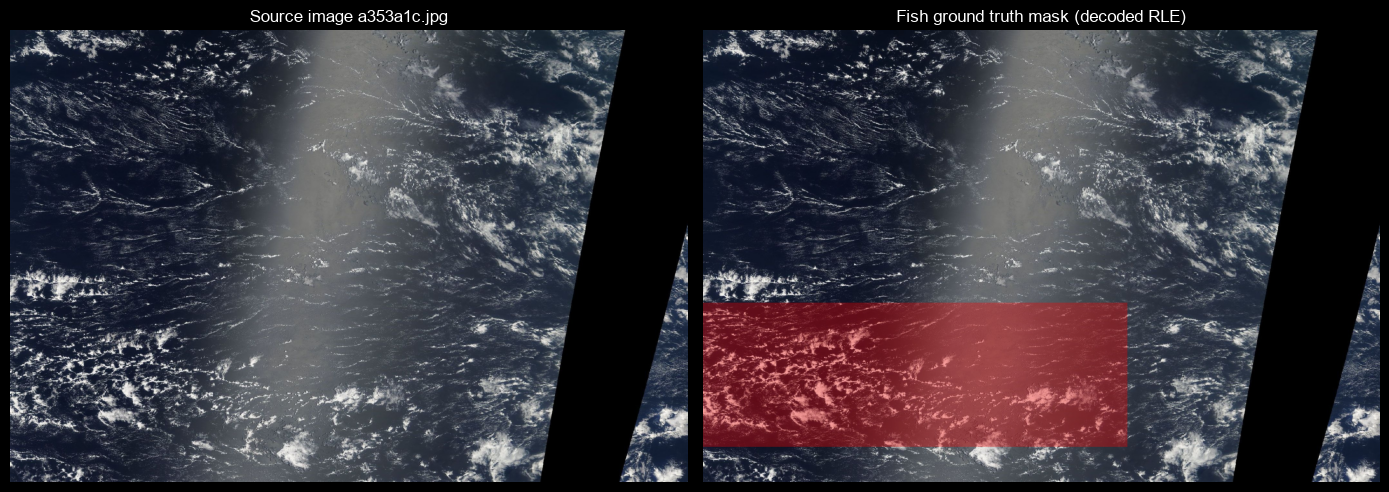

progress 100 / 2000 images (6.3 s)
progress 200 / 2000 images (12.6 s)
progress 300 / 2000 images (19.1 s)
progress 400 / 2000 images (25.5 s)
progress 500 / 2000 images (31.9 s)
progress 600 / 2000 images (38.2 s)
progress 700 / 2000 images (44.9 s)
progress 800 / 2000 images (52.0 s)
progress 900 / 2000 images (58.7 s)
progress 1000 / 2000 images (65.6 s)
progress 1100 / 2000 images (72.3 s)
progress 1200 / 2000 images (78.9 s)
progress 1300 / 2000 images (85.8 s)
progress 1400 / 2000 images (92.8 s)
progress 1500 / 2000 images (99.2 s)
progress 1600 / 2000 images (105.7 s)
progress 1700 / 2000 images (112.5 s)
progress 1800 / 2000 images (118.9 s)
progress 1900 / 2000 images (125.5 s)
progress 2000 / 2000 images (132.3 s)
Done: 2000 images in 132.3 s
Images X: (2000, 3, 192, 288) uint8 | masks Y: (2000, 4, 192, 288) uint8
Fish     present on 1018 images, mean pixel coverage 0.1514
Flower   present on  834 images, mean pixel coverage 0.1348
Gravel   present on 1114 images, mean pixel

In [3]:
# --------------------
# 3. Run length encodings and preprocessing
# --------------------

FULL_H, FULL_W = 1400, 2100  # source image size
IMG_H, IMG_W = 192, 288      # training resolution


def rle_decode(mask_rle, shape=(FULL_H, FULL_W)):
    # from kaggle encoded format
    if not isinstance(mask_rle, str):
        return np.zeros(shape, dtype=np.uint8)
    s = mask_rle.split()
    starts, lengths = [np.asarray(x, dtype=np.int64) for x in (s[0:][::2], s[1:][::2])]
    starts -= 1
    ends = starts + lengths
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    for lo, hi in zip(starts, ends):
        flat[lo:hi] = 1
    return flat.reshape(shape, order='F')


#
#


sample_row = df_raw[(df_raw['label'] == 'Fish') & df_raw['has_mask']].sample(
    1, random_state=RANDOM_STATE).iloc[0]
sample_img = Image.open(os.path.join(IMG_DIR, sample_row['image_id'])).convert('RGB')
sample_mask = rle_decode(sample_row['EncodedPixels'])
print('Sample image:', sample_row['image_id'], '| class:', sample_row['label'],
      '| mask coverage: {:.4f}'.format(sample_mask.mean()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(sample_img)
axes[0].set_title('Source image ' + sample_row['image_id'])
axes[1].imshow(sample_img)
axes[1].imshow(np.ma.masked_where(sample_mask == 0, sample_mask), cmap='autumn', alpha=0.35)
axes[1].set_title('Fish ground truth mask (decoded RLE)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

# take part of images to save time
N_SUBSET = 2000

rng = np.random.default_rng(RANDOM_STATE)
subset_ids = rng.choice(df_raw['image_id'].unique(), size=N_SUBSET, replace=False)

# RLE strings per image and class
rle_pivot = df_raw.pivot_table(index='image_id', columns='label',
                               values='EncodedPixels', aggfunc='first')[CLASSES]

X = np.zeros((N_SUBSET, 3, IMG_H, IMG_W), dtype=np.uint8)
Y = np.zeros((N_SUBSET, 4, IMG_H, IMG_W), dtype=np.uint8)

t0 = time.time()

# resize images to lowres
for i, img_id in enumerate(subset_ids):
    img = Image.open(os.path.join(IMG_DIR, img_id)).convert('RGB')
    img = img.resize((IMG_W, IMG_H), Image.BILINEAR)
    X[i] = np.asarray(img).transpose(2, 0, 1)
    for c, cls in enumerate(CLASSES):
        mask_full = rle_decode(rle_pivot.loc[img_id, cls])
        mask_small = Image.fromarray(mask_full * 255).resize((IMG_W, IMG_H), Image.NEAREST)
        Y[i, c] = (np.asarray(mask_small) > 0).astype(np.uint8)
    if (i + 1) % 100 == 0:
        print('progress {} / {} images ({:.1f} s)'.format(i + 1, N_SUBSET, time.time() - t0))

print('Done: {} images in {:.1f} s'.format(N_SUBSET, time.time() - t0))
print('Images X:', X.shape, X.dtype, '| masks Y:', Y.shape, Y.dtype)

# Class balance and mask coverage inside subset
for c, cls in enumerate(CLASSES):
    print('{:8s} present on {:4d} images, mean pixel coverage {:.4f}'.format(
        cls, int(Y[:, c].any(axis=(1, 2)).sum()), float(Y[:, c].mean())))

# Train / validation split of image indices
idx_train, idx_val = train_test_split(np.arange(N_SUBSET), test_size=0.2,
                                      random_state=RANDOM_STATE)
print('Train images: {} | validation images: {}'.format(len(idx_train), len(idx_val)))


In [4]:
# --------------------
# 4. PyTorch datasets and data loaders
# --------------------

# Color statistics from train part (images scaled to [0, 1])
x_train_float = X[idx_train].astype(np.float32) / 255.0
ch_mean = x_train_float.mean(axis=(0, 2, 3))
ch_std = x_train_float.std(axis=(0, 2, 3))
print('Channel mean:', np.round(ch_mean, 4))
print('Channel std: ', np.round(ch_std, 4))


class CloudDataset(Dataset):
    # uint8 arrays kept in ram, normalization on the fly
    def __init__(self, X_arr, Y_arr, mean, std, augment=False):
        self.X_arr = X_arr
        self.Y_arr = Y_arr
        self.mean = mean.astype(np.float32)[:, None, None]
        self.std = std.astype(np.float32)[:, None, None]
        self.augment = augment

    def __len__(self):
        return len(self.X_arr)

    def __getitem__(self, i):
        img = self.X_arr[i].astype(np.float32) / 255.0
        img = (img - self.mean) / self.std
        mask = self.Y_arr[i].astype(np.float32)
        if self.augment and random.random() < 0.5:
            img = np.ascontiguousarray(img[:, :, ::-1])
            mask = np.ascontiguousarray(mask[:, :, ::-1])
        return torch.from_numpy(img), torch.from_numpy(mask)


train_ds = CloudDataset(X[idx_train], Y[idx_train], ch_mean, ch_std, augment=True)
val_ds = CloudDataset(X[idx_val], Y[idx_val], ch_mean, ch_std, augment=False)

BATCH_SIZE = 8
loader_g = torch.Generator().manual_seed(RANDOM_STATE)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=loader_g)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False)

print('Train images:', len(train_ds), '| val images:', len(val_ds))
print('Batches per train epoch:', len(train_loader))

xb, yb = next(iter(train_loader))
print('Batch shapes: images {}, masks {}'.format(tuple(xb.shape), tuple(yb.shape)))


Channel mean: [0.2607 0.2788 0.3265]
Channel std:  [0.2306 0.2265 0.2136]
Train images: 1600 | val images: 400
Batches per train epoch: 200
Batch shapes: images (8, 3, 192, 288), masks (8, 4, 192, 288)


In [5]:
# --------------------
# 5. U-net convolution segment network
# --------------------


class DoubleConv(nn.Module):
    # (Conv2d => BatchNorm2d => ReLU) * 2
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x_in):
        return self.net(x_in)


class UNet(nn.Module):
    # Encoder-decoder with skip connections, 4 output channels (one per cloud class)
    def __init__(self, in_ch=3, n_classes=4, base_ch=16):
        super().__init__()
        self.enc1 = DoubleConv(in_ch, base_ch)             # 192 x 288
        self.enc2 = DoubleConv(base_ch, base_ch * 2)       # 96 x 144
        self.enc3 = DoubleConv(base_ch * 2, base_ch * 4)   # 48 x 72
        self.enc4 = DoubleConv(base_ch * 4, base_ch * 8)   # 24 x 36
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(base_ch * 8, base_ch * 16)  # 12 x 18
        self.up4 = nn.ConvTranspose2d(base_ch * 16, base_ch * 8, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(base_ch * 16, base_ch * 8)
        self.up3 = nn.ConvTranspose2d(base_ch * 8, base_ch * 4, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(base_ch * 8, base_ch * 4)
        self.up2 = nn.ConvTranspose2d(base_ch * 4, base_ch * 2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(base_ch * 4, base_ch * 2)
        self.up1 = nn.ConvTranspose2d(base_ch * 2, base_ch, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(base_ch * 2, base_ch)
        self.head = nn.Conv2d(base_ch, n_classes, kernel_size=1)

    def forward(self, x_in):
        e1 = self.enc1(x_in)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)  # as raw network result for the 4 classes


model = UNet().to(device)
n_params = sum(p.numel() for p in model.parameters())
print('U-Net parameters: {} ({:.2f}M)'.format(n_params, n_params / 1e6))

# 4 mask check channels at the input resolution
with torch.no_grad():
    dummy = torch.zeros(1, 3, IMG_H, IMG_W, device=device)
    print('Output shape for a dummy batch:', tuple(model(dummy).shape))


U-Net parameters: 1942628 (1.94M)
Output shape for a dummy batch: (1, 4, 192, 288)


In [6]:
# --------------------
# 6. Train run with early stop by validation dice
# --------------------


def dice_per_class(pred_bin, target):
    # Aggregated hard dice per class: intersections and areas summed over the whole set
    inter = (pred_bin * target).sum(dim=(0, 2, 3))
    denom = pred_bin.sum(dim=(0, 2, 3)) + target.sum(dim=(0, 2, 3))
    return (2 * inter + 1.0) / (denom + 1.0)


class BCEDiceLoss(nn.Module):
    # Binary cross-entropy handles per-pixel correctness, soft dice handles class imbalance
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, target):
        probs = torch.sigmoid(logits)
        inter = (probs * target).sum(dim=(0, 2, 3))
        denom = probs.sum(dim=(0, 2, 3)) + target.sum(dim=(0, 2, 3))
        soft_dice = 1 - ((2 * inter + 1.0) / (denom + 1.0)).mean()
        return 0.5 * self.bce(logits, target) + 0.5 * soft_dice


def evaluate(model, loader, loss_fn, thr=0.5):
    model.eval()
    loss_sum, n_seen = 0.0, 0
    inter_c = torch.zeros(4)
    denom_c = torch.zeros(4)
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss_sum += loss_fn(logits, yb).item() * len(xb)
            n_seen += len(xb)
            pred = (torch.sigmoid(logits) > thr).float()
            inter_c += (pred * yb).sum(dim=(0, 2, 3)).cpu()
            denom_c += (pred.sum(dim=(0, 2, 3)) + yb.sum(dim=(0, 2, 3))).cpu()
    return loss_sum / n_seen, ((2 * inter_c + 1.0) / (denom_c + 1.0)).numpy()


EPOCHS = 20
LR = 0.001
PATIENCE = 3  # stop after n epochs without improvement

optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=2)
loss_fn = BCEDiceLoss()

print('Starting training: max {} epochs, early stop patience {}, {} batches per epoch'.format(
    EPOCHS, PATIENCE, len(train_loader)))

history = []
best_dice = -1.0
best_state = None
epochs_no_improve = 0
t_start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        # gradient clip to protect from exploding gradient
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        train_loss += loss.item() * len(xb)
    train_loss /= len(train_ds)

    val_loss, dice_pc = evaluate(model, val_loader, loss_fn)
    val_dice = float(dice_pc.mean())
    scheduler.step(val_dice)
    cur_lr = optimizer.param_groups[0]['lr']

    history.append({'epoch': epoch,
                    'train_loss': train_loss,
                    'val_loss': val_loss,
                    'dice_fish': float(dice_pc[0]),
                    'dice_flower': float(dice_pc[1]),
                    'dice_gravel': float(dice_pc[2]),
                    'dice_sugar': float(dice_pc[3]),
                    'dice_mean': val_dice,
                    'lr': cur_lr})

    marker = ''
    if val_dice > best_dice:
        best_dice = val_dice
        best_state = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
        marker = '  <-- best'
    else:
        epochs_no_improve += 1

    print('Epoch {:2d}/{} | train loss {:.4f} | val loss {:.4f} | Dice: Fish {:.3f} '
          'Flower {:.3f} Gravel {:.3f} Sugar {:.3f} | mean {:.4f} | lr {:.5f}{}'
          .format(epoch, EPOCHS, train_loss, val_loss,
                  dice_pc[0], dice_pc[1], dice_pc[2], dice_pc[3], val_dice, cur_lr, marker))

    if epochs_no_improve >= PATIENCE:
        print('Early stop: no improvements for {} epochs'.format(PATIENCE))
        break

print('Training finished in {:.1f} min'.format((time.time() - t_start) / 60))

# Restore and persist the best model
model.load_state_dict(best_state)
torch.save({'state_dict': best_state,
            'img_size': (IMG_H, IMG_W),
            'classes': CLASSES,
            'val_dice': best_dice},
           os.path.join(output_dir, 'unet_clouds_best.pt'))
print('Best checkpoint (val Dice {:.4f}) saved to unet_clouds_best.pt'.format(best_dice))


Starting training: max 20 epochs, early stop patience 3, 200 batches per epoch
Epoch  1/20 | train loss 0.6064 | val loss 0.5432 | Dice: Fish 0.000 Flower 0.385 Gravel 0.459 Sugar 0.529 | mean 0.3431 | lr 0.00100  <-- best
Epoch  2/20 | train loss 0.5149 | val loss 0.4991 | Dice: Fish 0.000 Flower 0.551 Gravel 0.408 Sugar 0.567 | mean 0.3816 | lr 0.00100  <-- best
Epoch  3/20 | train loss 0.4911 | val loss 0.5605 | Dice: Fish 0.088 Flower 0.372 Gravel 0.333 Sugar 0.509 | mean 0.3257 | lr 0.00100
Epoch  4/20 | train loss 0.4804 | val loss 0.4965 | Dice: Fish 0.365 Flower 0.522 Gravel 0.467 Sugar 0.565 | mean 0.4796 | lr 0.00100  <-- best
Epoch  5/20 | train loss 0.4700 | val loss 0.4534 | Dice: Fish 0.450 Flower 0.583 Gravel 0.459 Sugar 0.557 | mean 0.5123 | lr 0.00100  <-- best
Epoch  6/20 | train loss 0.4652 | val loss 0.4485 | Dice: Fish 0.476 Flower 0.568 Gravel 0.428 Sugar 0.603 | mean 0.5187 | lr 0.00100  <-- best
Epoch  7/20 | train loss 0.4587 | val loss 0.4830 | Dice: Fish 0.42

In [7]:
# --------------------
# 7. Learning diagram
# --------------------

history_df = pd.DataFrame(history)
display(history_df.round(4))

best_epoch = int(history_df.loc[history_df['dice_mean'].idxmax(), 'epoch'])

fig = make_subplots(rows=1, cols=2,
                    subplot_titles=('Loss per epoch', 'Validation Dice per epoch'))

fig.add_trace(go.Scatter(x=history_df['epoch'], y=history_df['train_loss'],
                         mode='lines+markers', name='train loss'), row=1, col=1)
fig.add_trace(go.Scatter(x=history_df['epoch'], y=history_df['val_loss'],
                         mode='lines+markers', name='val loss'), row=1, col=1)

class_colors = {'Fish': '#4c78a8', 'Flower': '#54a24b',
                'Gravel': '#f58518', 'Sugar': '#b279a2'}
for cls in CLASSES:
    fig.add_trace(go.Scatter(x=history_df['epoch'], y=history_df['dice_' + cls.lower()],
                             mode='lines+markers', name='Dice ' + cls,
                             marker_color=class_colors[cls]), row=1, col=2)

fig.add_vline(x=best_epoch, line_dash='dash', line_color='grey',
              annotation_text='best epoch', row=1, col=2)

loss_top = float(np.ceil(history_df[['train_loss', 'val_loss']].values.max() * 10) / 10)
fig.update_yaxes(title_text='loss', range=[0, loss_top], row=1, col=1)
fig.update_yaxes(title_text='Dice', range=[0, 1.0], row=1, col=2)
fig.update_xaxes(title_text='epoch', row=1, col=1)
fig.update_xaxes(title_text='epoch', row=1, col=2)
fig.update_layout(title='U-Net training history', width=1050, height=430)
fig.show()


,epoch,train_loss,val_loss,dice_fish,dice_flower,dice_gravel,dice_sugar,dice_mean,lr
0,1,0.6064,0.5432,0.0000,0.3848,0.4589,0.5289,0.3431,0.0010
1,2,0.5149,0.4991,0.0000,0.5515,0.4079,0.5672,0.3816,0.0010
2,3,0.4911,0.5605,0.0880,0.3723,0.3332,0.5092,0.3257,0.0010
3,4,0.4804,0.4965,0.3647,0.5223,0.4668,0.5648,0.4796,0.0010
4,5,0.4700,0.4534,0.4496,0.5834,0.4589,0.5573,0.5123,0.0010
5,6,0.4652,0.4485,0.4761,0.5675,0.4278,0.6034,0.5187,0.0010
6,7,0.4587,0.4830,0.4258,0.5231,0.4153,0.5624,0.4817,0.0010
7,8,0.4542,0.4563,0.4933,0.5138,0.4870,0.5777,0.5179,0.0010
8,9,0.4443,0.4513,0.4981,0.6125,0.4524,0.5169,0.5200,0.0010
9,10,0.4440,0.4291,0.4697,0.6099,0.4517,0.5977,0.5323,0.0010


In [8]:
# --------------------
# 8. Final evaluation of the best checkpoint
# --------------------

checkpoint = torch.load(os.path.join(output_dir, 'unet_clouds_best.pt'),
                        map_location=device, weights_only=True)
model.load_state_dict(checkpoint['state_dict'])
print('Loaded checkpoint with val Dice = {:.4f}'.format(float(checkpoint['val_dice'])))

# Non-augmented loader for train metrics
train_eval_loader = DataLoader(
    CloudDataset(X[idx_train], Y[idx_train], ch_mean, ch_std, augment=False),
    batch_size=16, shuffle=False)

train_loss_final, train_dice_pc = evaluate(model, train_eval_loader, loss_fn)
val_loss_final, val_dice_pc = evaluate(model, val_loader, loss_fn)

dice_table = pd.DataFrame({'class': CLASSES,
                           'dice_train': np.round(train_dice_pc, 4),
                           'dice_val': np.round(val_dice_pc, 4)})
print('Aggregated hard Dice by class (threshold 0.5):')
display(dice_table)
print('Mean Dice: train {:.4f} | val {:.4f}'.format(
    float(train_dice_pc.mean()), float(val_dice_pc.mean())))

# Validation probabilities for threshold analysis
val_probs = np.zeros((len(val_ds), 4, IMG_H, IMG_W), dtype=np.float32)
pos = 0
model.eval()
with torch.no_grad():
    for xb, _ in val_loader:
        out = torch.sigmoid(model(xb.to(device))).cpu().numpy()
        val_probs[pos:pos + len(out)] = out
        pos += len(out)

Y_val = Y[idx_val].astype(np.float32)


def aggregated_dice(preds_bin, target):
    # hard Dice per class, accumulated on the dataset
    inter = (preds_bin * target).sum(axis=(0, 2, 3))
    denom = preds_bin.sum(axis=(0, 2, 3)) + target.sum(axis=(0, 2, 3))
    return (2 * inter + 1.0) / (denom + 1.0)


def kaggle_dice(preds_bin, target):
    # kaggle approach: per class, mean for images where the true mask
    out = []
    for c in range(4):
        p = preds_bin[:, c].reshape(len(preds_bin), -1)
        t = target[:, c].reshape(len(target), -1)
        active = (p.sum(axis=1) > 0) | (t.sum(axis=1) > 0)
        dices = (2 * (p * t).sum(axis=1) + 1.0) / (p.sum(axis=1) + t.sum(axis=1) + 1.0)
        out.append(float(dices[active].mean()) if active.any() else 0.0)
    return np.array(out)


threshold_rows = []
for thr in [0.3, 0.4, 0.5, 0.6, 0.7]:
    preds_bin = (val_probs > thr).astype(np.float32)
    agg = aggregated_dice(preds_bin, Y_val)
    kg = kaggle_dice(preds_bin, Y_val)
    threshold_rows.append({'threshold': thr,
                           'agg_fish': round(float(agg[0]), 4),
                           'agg_flower': round(float(agg[1]), 4),
                           'agg_gravel': round(float(agg[2]), 4),
                           'agg_sugar': round(float(agg[3]), 4),
                           'agg_mean': round(float(agg.mean()), 4),
                           'kaggle_mean': round(float(kg.mean()), 4)})
threshold_df = pd.DataFrame(threshold_rows)
print('Threshold analysis on validation:')
display(threshold_df)

best_thr_row = threshold_df.loc[threshold_df['agg_mean'].idxmax()]
best_thr = float(best_thr_row['threshold'])
print('Best threshold by mean Dice: {:.1f} (agg mean {:.4f})'.format(
    best_thr, float(best_thr_row['agg_mean'])))

preds_best = (val_probs > best_thr).astype(np.float32)
final_kaggle = kaggle_dice(preds_best, Y_val)
print('Kaggle-style Dice at best threshold: Fish {:.4f} Flower {:.4f} Gravel {:.4f} '
      'Sugar {:.4f} | mean {:.4f}'.format(final_kaggle[0], final_kaggle[1],
                                          final_kaggle[2], final_kaggle[3],
                                          float(final_kaggle.mean())))

# Add logs
results_row = {
    'timestamp': time.strftime('%Y-%m-%d %H:%M:%S'),
    'model': 'UNet base_ch=16, {:.2f}M params'.format(n_params / 1e6),
    'hyperparameters': 'img {}x{}, subset {} (train {}/val {}), batch {}, Adam lr={}, '
                       'BCE+Dice loss, {} epochs, early stop patience {}, hflip aug'
                       .format(IMG_H, IMG_W, N_SUBSET, len(idx_train), len(idx_val),
                               BATCH_SIZE, LR, len(history_df), PATIENCE),
    'dice_mean_train': round(float(train_dice_pc.mean()), 4),
    'dice_mean_val': round(float(val_dice_pc.mean()), 4),
    'dice_fish_val': round(float(val_dice_pc[0]), 4),
    'dice_flower_val': round(float(val_dice_pc[1]), 4),
    'dice_gravel_val': round(float(val_dice_pc[2]), 4),
    'dice_sugar_val': round(float(val_dice_pc[3]), 4),
    'best_threshold': round(best_thr, 1),
    'dice_mean_val_best_thr': round(float(best_thr_row['agg_mean']), 4),
    'dice_kaggle_mean_best_thr': round(float(final_kaggle.mean()), 4),
}
results_df = pd.DataFrame([results_row])
csv_path = os.path.join(output_dir, 'model_results.csv')
results_df.to_csv(csv_path, mode='a', header=not os.path.exists(csv_path), index=False)
print('Metrics appended to', csv_path)
display(results_df)


Loaded checkpoint with val Dice = 0.5600
Aggregated hard Dice by class (threshold 0.5):


,class,dice_train,dice_val
0,Fish,0.4957,0.5035
1,Flower,0.6805,0.6181
2,Gravel,0.5447,0.5087
3,Sugar,0.5918,0.6098


Mean Dice: train 0.5782 | val 0.5600
Threshold analysis on validation:


,threshold,agg_fish,agg_flower,agg_gravel,agg_sugar,agg_mean,kaggle_mean
0,0.3,0.4924,0.6163,0.5200,0.6098,0.5596,0.3661
1,0.4,0.5001,0.6183,0.5175,0.6138,0.5624,0.3680
2,0.5,0.5035,0.6181,0.5087,0.6098,0.5600,0.3607
3,0.6,0.5014,0.6153,0.4922,0.5983,0.5518,0.3519
4,0.7,0.4858,0.6050,0.4572,0.5745,0.5306,0.3351


Best threshold by mean Dice: 0.4 (agg mean 0.5624)
Kaggle-style Dice at best threshold: Fish 0.3278 Flower 0.3851 Gravel 0.3158 Sugar 0.4433 | mean 0.3680
Metrics appended to csv_output\model_results.csv


,timestamp,model,hyperparameters,dice_mean_train,dice_mean_val,dice_fish_val,dice_flower_val,dice_gravel_val,dice_sugar_val,best_threshold,dice_mean_val_best_thr,dice_kaggle_mean_best_thr
0,2026-11-18 21:16:59,"UNet base_ch=16, 1.94M params","img 192x288, subset 2000 (train 1600/val 400),...",0.5782,0.56,0.5035,0.6181,0.5087,0.6098,0.4,0.5624,0.368


Validation images shown: ['c46d59f.jpg', '773dbfd.jpg', 'f4d657a.jpg']


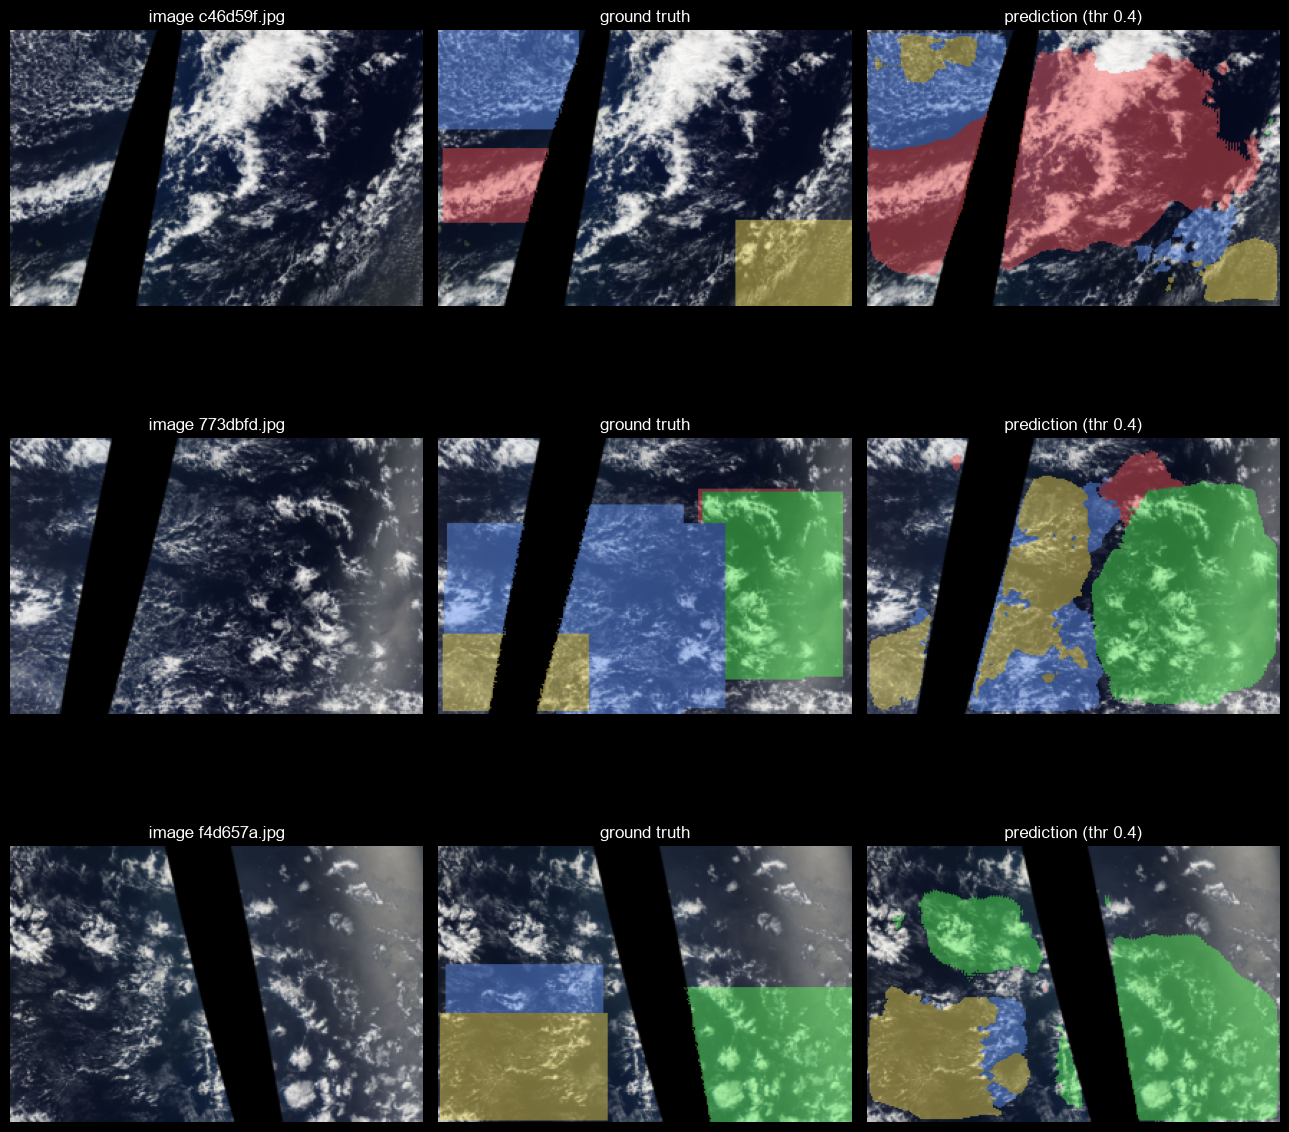

Cloud structure organization on the validation set:


,class,frequency,mean_coverage_percent
0,Fish,0.5750,16.1806
1,Flower,0.3900,12.3181
2,Gravel,0.5475,14.8450
3,Sugar,0.7025,17.0276


In [9]:
# --------------------
# 9. Qualitative analysis and cloud organization
# --------------------

# Colors for clouds: Fish-red, Flower-green, Gravel-blue, Sugar-yellow
CLASS_COLORS = np.array([[1.0, 0.35, 0.35],
                         [0.35, 1.0, 0.35],
                         [0.4, 0.6, 1.0],
                         [1.0, 0.9, 0.35]])


def clouds_colors(masks_4hw, alpha=0.45):
    rgba = np.zeros((IMG_H, IMG_W, 4), dtype=np.float32)
    for c in range(4):
        m = masks_4hw[c] > 0
        rgba[m, :3] = CLASS_COLORS[c]
        rgba[m, 3] = alpha
    return rgba


# Validation images where at least two classes are present
n_classes_val = (Y[idx_val].sum(axis=(2, 3)) > 0).sum(axis=1)
show_ids = np.where(n_classes_val >= 2)[0][:3]
print('Validation images shown:', [subset_ids[idx_val][k] for k in show_ids])

fig, axes = plt.subplots(len(show_ids), 3, figsize=(13, 4.4 * len(show_ids)))
axes = np.atleast_2d(axes)
for r, local_id in enumerate(show_ids):
    img = X[idx_val][local_id].astype(np.float32) / 255.0
    preds = (val_probs[local_id] > best_thr).astype(np.uint8)
    axes[r, 0].imshow(img.transpose(1, 2, 0))
    axes[r, 0].set_title('image ' + subset_ids[idx_val][local_id])
    axes[r, 1].imshow(img.transpose(1, 2, 0))
    axes[r, 1].imshow(clouds_colors(Y[idx_val][local_id]))
    axes[r, 1].set_title('ground truth')
    axes[r, 2].imshow(img.transpose(1, 2, 0))
    axes[r, 2].imshow(clouds_colors(preds))
    axes[r, 2].set_title('prediction (thr {:.1f})'.format(best_thr))
    for ax in axes[r]:
        ax.axis('off')
plt.tight_layout()
plt.show()

# Cloud organization: how often each cloud appears and how much of the image it covers
orga_rows = []
for c, cls in enumerate(CLASSES):
    present = Y_val[:, c].sum(axis=(1, 2)) > 0
    orga_rows.append({'class': cls,
                      'frequency': round(float(present.mean()), 4),
                      'mean_coverage_percent': round(float(Y_val[:, c].mean() * 100), 4)})
orga_df = pd.DataFrame(orga_rows)
print('Cloud structure organization on the validation set:')
display(orga_df)

fig = px.bar(orga_df, x='class', y='frequency', color='class',
             title='Frequency of cloud structures on validation images',
             labels={'frequency': 'share of images'})
fig.update_yaxes(range=[0, 0.8])
fig.show()


In [10]:
# =====================
# 10. Conclusion
# =====================
#
# Типы облаков [рыбы, цветы, гравий, сахар].
# 5.5 тыс фото для обучения. Сахар получился самый часто встречаемый (почти 0.68 случаев).
# Меньше всего встречался цветной тип (0.43).
# Около половины фото имеют сразу 2 типа облаков. Самая частая пара гравий и сахар (0.37) может потому, что модель видит их похожими.
#
# Для работы взл 1000 фото из общих 5тыс и потом взял 2000 фото.
# По итогам (csv_output/model_results.csv) видно, что на большем количестве фоток. метрики подрасли. В общем так и должно же быть - больше данных для обучения, лушче происходит классификация
# Для работы на ноуте сделал  даунскейлинг фоток в 192х288
# Сама модель unet с шринкингом и енкодеромм 16-32-64-128-256. Кстати для разрешения 1400х2100 по идее уменьшение размера должно поломаться т.к. не делится без остатка на целое число пикселей (350×525 / 2). Делает поиск по 4 каналам (точки, царапины..) в виде 0.0-1.00
#
# Для обучения 20 эпох с остановом при отсутствии улучшений метрик после PATIENCE = 3. шаг сдвига LR 0.001
#
# Облака с цветами выглядят, как самые контрастные и не растянутые в пространстве.
# Сахар и гравий растянуты на фото

